# Simulación Multiactivo
María Fernanda Gómez Flores

Simulación de Procesos Financieros

En esta tarea voy a comparar los portafolios tomando primero los activos como independientes y después considerando sus correlaciones. En los dos casos uso $100,000 MXN y simulo un año.

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Parte A. Nvidia, Bimbo, Cemex y AstraZeneca

Primero voy a repetir el ejercicio de Monte Carlo que hicimos en clase, pero ahora también voy a considerar la correlación entre los activos y el dólar.

### 1. Descargar datos y calcular rendimientos

In [2]:
tickers = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN', 'MXN=X']

df = yf.download(tickers, start='2023-11-02', end='2026-11-03', auto_adjust=True, progress=False)['Close']
df = df[tickers]

# Precios del 2 de noviembre que usamos en clase
df.loc[pd.Timestamp('2026-11-02'), ['AZN', 'BIMBOA.MX', 'CEMEXCPO.MX', 'NVDA', 'MXN=X']] = [186.58, 66.18, 20.23, 202.06, 18.58]
df = df.sort_index().dropna()
df.tail()

Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
Date,,,,,
2026-10-27,217.940002,64.849998,19.730000,170.080002,18.55020
2026-10-28,215.380005,61.830002,19.700001,169.509995,18.68704
2026-10-29,213.660004,63.689999,20.480000,174.399994,18.63179
2026-10-30,204.639999,66.180000,20.230000,186.649994,18.85210
2026-11-02,202.060000,66.180000,20.230000,186.580000,18.58000


In [3]:
rets = np.log(df / df.shift(1)).dropna()
mu = rets.mean()
sigma = rets.std(ddof=1)

print(mu)
print(sigma)

Ticker
NVDA           0.002073
BIMBOA.MX     -0.000171
CEMEXCPO.MX    0.000783
AZN            0.000593
MXN=X          0.000080
dtype: float64
Ticker
NVDA           0.029767
BIMBOA.MX      0.018816
CEMEXCPO.MX    0.020762
AZN            0.015860
MXN=X          0.006956
dtype: float64


### 2. Revisar las correlaciones

Aquí puedo ver si los rendimientos están relacionados aunque las empresas sean de sectores distintos.

In [4]:
R = rets.corr()
R

Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
Ticker,,,,,
NVDA,1.000000,0.080729,0.216103,0.014629,0.017954
BIMBOA.MX,0.080729,1.000000,0.201294,0.110442,0.051845
CEMEXCPO.MX,0.216103,0.201294,1.000000,0.095362,-0.025667
AZN,0.014629,0.110442,0.095362,1.000000,-0.006462
MXN=X,0.017954,0.051845,-0.025667,-0.006462,1.000000


### 3. Simular independiente y correlacionado

Uso las mismas medias y volatilidades. La diferencia es que en la segunda simulación utilizo Cholesky para que los movimientos sí tengan correlación.

In [5]:
V0 = 100000
T = 1
M = 10000
S0 = df.loc[pd.Timestamp('2026-11-02')]

np.random.seed(32)
epsilon = np.random.normal(0, 1, (len(tickers), M))

L = np.linalg.cholesky(R)
Z = L @ epsilon

precios_ind = pd.DataFrame(index=range(M), columns=tickers, dtype=float)
precios_corr = pd.DataFrame(index=range(M), columns=tickers, dtype=float)

for i, ticker in enumerate(tickers):
    precios_ind[ticker] = S0[ticker] * np.exp(mu[ticker] * 252 * T + sigma[ticker] * np.sqrt(252 * T) * epsilon[i])
    precios_corr[ticker] = S0[ticker] * np.exp(mu[ticker] * 252 * T + sigma[ticker] * np.sqrt(252 * T) * Z[i])

precios_corr.head()

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
0,288.880937,108.395252,24.736349,258.977535,19.567606
1,542.249405,82.593210,30.388556,209.751194,23.155567
2,448.269406,43.434028,23.828139,201.839823,19.301340
3,352.163369,56.927502,17.679647,192.823314,20.567478
4,491.912695,54.283629,18.035210,166.572702,19.489263


### 4. Cantidad de acciones

Estos son los tres casos que vamos a comparar. El caso 2 es el que ya habíamos trabajado con 25% en cada acción. Los otros dos son los esquemas que aparecen en el ejercicio de referencia para esta tarea.

In [6]:
acciones = ['NVDA', 'BIMBOA.MX', 'CEMEXCPO.MX', 'AZN']
pesos = {
    'Caso 1': [1, 0, 0, 0],
    'Caso 2': [0.25, 0.25, 0.25, 0.25],
    'Caso 3': [0.1, 0.2, 0.3, 0.4]
}

N = {}
saldo = {}

for nombre, w in pesos.items():
    N[nombre] = {}
    gastado = 0
    for i, ticker in enumerate(acciones):
        precio_mxn = S0[ticker] * S0['MXN=X'] if ticker in ['NVDA', 'AZN'] else S0[ticker]
        N[nombre][ticker] = int(w[i] * V0 / precio_mxn)
        gastado += N[nombre][ticker] * precio_mxn
    saldo[nombre] = V0 - gastado

pd.DataFrame(N).T

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN
Caso 1,26,0,0,0
Caso 2,6,377,1235,7
Caso 3,2,302,1482,11


Como estamos comprando acciones enteras, guardo el dinero que sobra sin invertir para que el capital inicial siga siendo $100,000.

### 5. Valor final de los portafolios

Con las cantidades que compré, calculo cuánto vale cada portafolio al final del año. Las acciones en dólares las convierto a pesos con el tipo de cambio simulado.

In [7]:
VT_ind = {}
VT_corr = {}

for nombre in pesos:
    n = N[nombre]
    VT_ind[nombre] = (
        n['NVDA'] * precios_ind['NVDA'] * precios_ind['MXN=X']
        + n['BIMBOA.MX'] * precios_ind['BIMBOA.MX']
        + n['CEMEXCPO.MX'] * precios_ind['CEMEXCPO.MX']
        + n['AZN'] * precios_ind['AZN'] * precios_ind['MXN=X']
        + saldo[nombre]
    )
    VT_corr[nombre] = (
        n['NVDA'] * precios_corr['NVDA'] * precios_corr['MXN=X']
        + n['BIMBOA.MX'] * precios_corr['BIMBOA.MX']
        + n['CEMEXCPO.MX'] * precios_corr['CEMEXCPO.MX']
        + n['AZN'] * precios_corr['AZN'] * precios_corr['MXN=X']
        + saldo[nombre]
    )

### 6. Comparación de los tres casos

In [8]:
resumen = []
for nombre in pesos:
    for metodo, vt in [('Independiente', VT_ind[nombre]), ('Correlacionado', VT_corr[nombre])]:
        resumen.append({
            'Caso': nombre,
            'Método': metodo,
            'Valor promedio': vt.mean(),
            'Ganancia promedio': (vt - V0).mean(),
            'Volatilidad (%)': (vt / V0 - 1).std() * 100,
            'Prob. pérdida (%)': (vt < V0).mean() * 100
        })

pd.DataFrame(resumen).round(2)

,Caso,Método,Valor promedio,Ganancia promedio,Volatilidad (%),Prob. pérdida (%)
0,Caso 1,Independiente,192598.51,92598.51,98.66,12.83
1,Caso 1,Correlacionado,192818.15,92818.15,99.26,12.87
2,Caso 2,Independiente,134219.67,34219.67,28.42,7.96
3,Caso 2,Correlacionado,134348.47,34348.47,31.81,11.26
4,Caso 3,Independiente,124556.03,24556.03,21.36,11.01
5,Caso 3,Correlacionado,124665.60,24665.60,24.19,14.36


### Caso 1

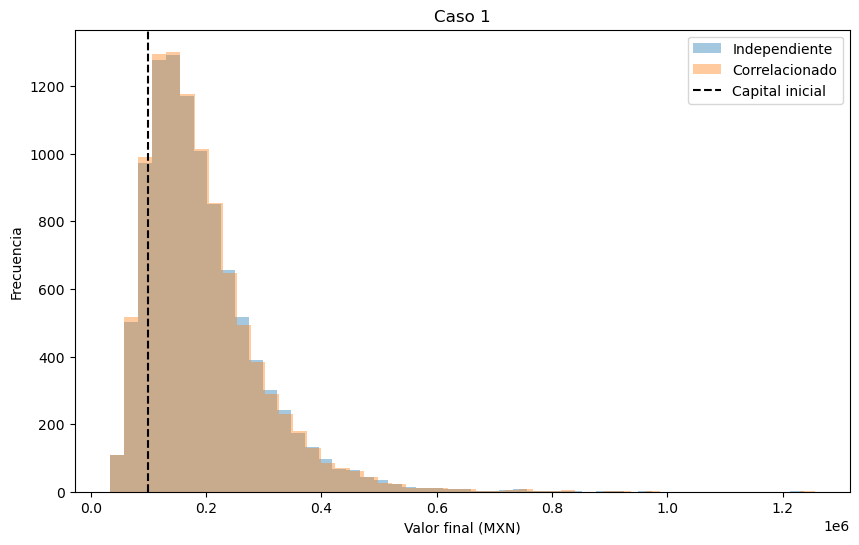

In [9]:
plt.figure(figsize=(10, 6))
plt.hist(VT_ind['Caso 1'], bins=50, alpha=0.4, label='Independiente')
plt.hist(VT_corr['Caso 1'], bins=50, alpha=0.4, label='Correlacionado')
plt.axvline(V0, color='black', linestyle='--', label='Capital inicial')
plt.title('Caso 1')
plt.xlabel('Valor final (MXN)')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

En este caso invertí todo en Nvidia. Aunque sea una sola acción, también influye el dólar porque estoy calculando el valor final en pesos.

### Caso 2

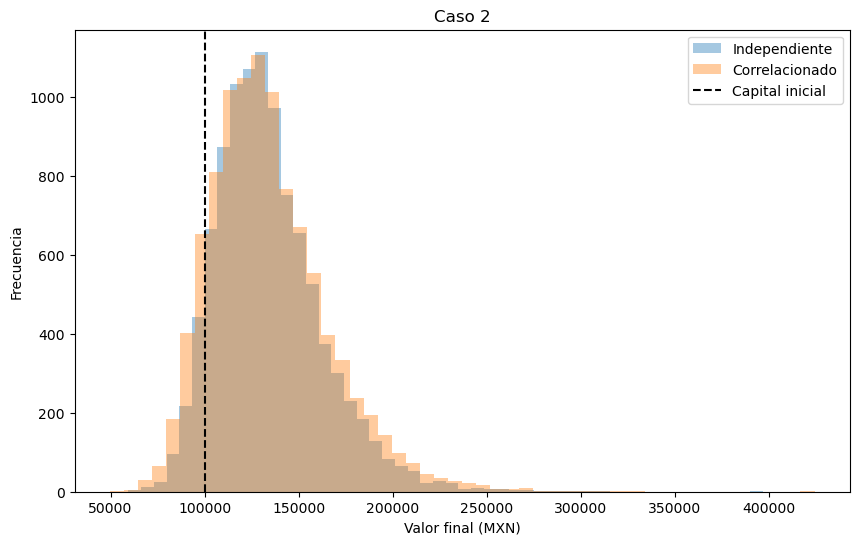

In [10]:
plt.figure(figsize=(10, 6))
plt.hist(VT_ind['Caso 2'], bins=50, alpha=0.4, label='Independiente')
plt.hist(VT_corr['Caso 2'], bins=50, alpha=0.4, label='Correlacionado')
plt.axvline(V0, color='black', linestyle='--', label='Capital inicial')
plt.title('Caso 2')
plt.xlabel('Valor final (MXN)')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

Aquí repartí el dinero entre las cuatro empresas. Voy a comparar qué tanto cambia la dispersión cuando dejo de suponer que son independientes.

### Caso 3

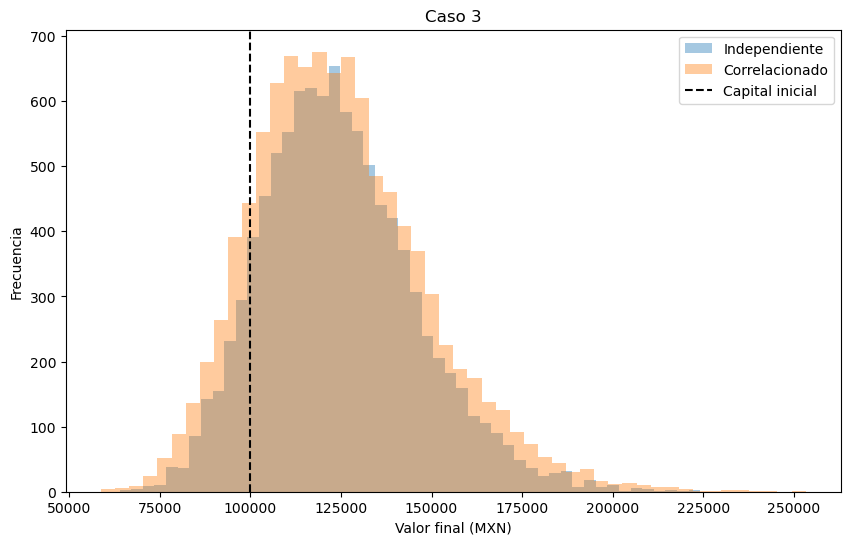

In [11]:
plt.figure(figsize=(10, 6))
plt.hist(VT_ind['Caso 3'], bins=50, alpha=0.4, label='Independiente')
plt.hist(VT_corr['Caso 3'], bins=50, alpha=0.4, label='Correlacionado')
plt.axvline(V0, color='black', linestyle='--', label='Capital inicial')
plt.title('Caso 3')
plt.xlabel('Valor final (MXN)')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

En este caso cambié los porcentajes de inversión. La diferencia entre las dos distribuciones depende de las correlaciones y de cuánto invertí en cada acción.

**Lo que observo en A:** Que las empresas estén en sectores diferentes no quiere decir que sus rendimientos sean independientes. Al considerar la correlación pueden cambiar la volatilidad y la probabilidad de perder dinero, como se observa en la tabla y en las gráficas.

# Parte B. Apple, Microsoft y Nvidia

Ahora voy a usar el ejercicio de Cholesky de clase y voy a comparar los tres esquemas de inversión con $100,000 MXN.

### 1. Datos y covarianza

In [12]:
tickers2 = ['AAPL', 'MSFT', 'NVDA']
prices = yf.download(tickers2, start='2025-11-10', end='2026-11-10', auto_adjust=True, progress=False)['Close']
prices = prices[tickers2].dropna()

rets2 = np.log(prices / prices.shift(1)).dropna()
Sigma = rets2.cov()
L2 = np.linalg.cholesky(Sigma)

print(rets2.corr())
print(Sigma)
L2

Ticker      AAPL      MSFT      NVDA
Ticker                              
AAPL    1.000000  0.160278  0.043845
MSFT    0.160278  1.000000  0.231188
NVDA    0.043845  0.231188  1.000000
Ticker      AAPL      MSFT      NVDA
Ticker                              
AAPL    0.000249  0.000053  0.000017
MSFT    0.000053  0.000447  0.000118
NVDA    0.000017  0.000118  0.000581


array([[0.01577947, 0.        , 0.        ],
       [0.00338707, 0.02085924, 0.        ],
       [0.00105688, 0.00547419, 0.0234515 ]])

### 2. Simular independiente y correlacionado

En el independiente uso la volatilidad de cada acción. Para el correlacionado uso Cholesky con la matriz de covarianzas, igual que lo hicimos en clase.

In [13]:
mu2 = rets2.mean().values * 252
sigma2 = rets2.std(ddof=1).values
S02 = prices.iloc[-1].values

M2 = 10000
np.random.seed(67)
epsilon2 = np.random.normal(0, 1, (len(tickers2), M2))

Z_ind2 = sigma2[:, None] * epsilon2
Z_corr2 = L2 @ epsilon2

ST_ind2 = S02 * np.exp(mu2 + np.sqrt(252) * Z_ind2.T)
ST_corr2 = S02 * np.exp(mu2 + np.sqrt(252) * Z_corr2.T)

pd.DataFrame(ST_corr2, columns=tickers2).head()

,AAPL,MSFT,NVDA
0,608.520432,655.011929,188.676945
1,475.546410,493.777536,226.621020
2,346.881445,761.339214,250.869640
3,624.350526,402.342305,133.933816
4,441.247111,476.333155,144.786752


### 3. Invertir los $100,000 MXN

Para poder calcular las acciones uso el tipo de cambio de $18.58 MXN por dólar que anotamos en el ejercicio A el 2 de noviembre. En esta parte lo dejo fijo para comparar únicamente la correlación de las tres acciones.

In [14]:
V0 = 100000
tc = 18.58
pesos2 = {
    'Esquema 1': [1, 0, 0],
    'Esquema 2': [0.33, 0.33, 0.34],
    'Esquema 3': [0.2, 0.2, 0.6]
}

N2 = {}
VT_ind2 = {}
VT_corr2 = {}
PnL_ind2 = {}
PnL_corr2 = {}

for nombre, w in pesos2.items():
    N2[nombre] = (V0 / tc) * np.array(w) / S02
    VT_ind2[nombre] = (ST_ind2 @ N2[nombre]) * tc
    VT_corr2[nombre] = (ST_corr2 @ N2[nombre]) * tc
    PnL_ind2[nombre] = VT_ind2[nombre] - V0
    PnL_corr2[nombre] = VT_corr2[nombre] - V0

pd.DataFrame(N2, index=tickers2).T

,AAPL,MSFT,NVDA
Esquema 1,15.347262,0.000000,0.000000
Esquema 2,5.064596,3.257829,10.241925
Esquema 3,3.069452,1.974442,18.073985


### 4. Resultados

In [15]:
resumen2 = []
for nombre in pesos2:
    for metodo, pnl in [('Independiente', PnL_ind2[nombre]), ('Correlacionado', PnL_corr2[nombre])]:
        resumen2.append({
            'Esquema': nombre,
            'Método': metodo,
            'Ganancia promedio': pnl.mean(),
            'Volatilidad (%)': (pnl / V0).std() * 100,
            'Prob. pérdida (%)': (pnl < 0).mean() * 100
        })

pd.DataFrame(resumen2).round(2)

,Esquema,Método,Ganancia promedio,Volatilidad (%),Prob. pérdida (%)
0,Esquema 1,Independiente,34897.59,34.15,14.06
1,Esquema 1,Correlacionado,34897.59,34.15,14.06
2,Esquema 2,Independiente,15408.29,21.69,24.97
3,Esquema 2,Correlacionado,15394.48,24.56,28.39
4,Esquema 3,Independiente,8225.35,25.34,41.57
5,Esquema 3,Correlacionado,8201.89,27.43,42.84


### Esquema 1

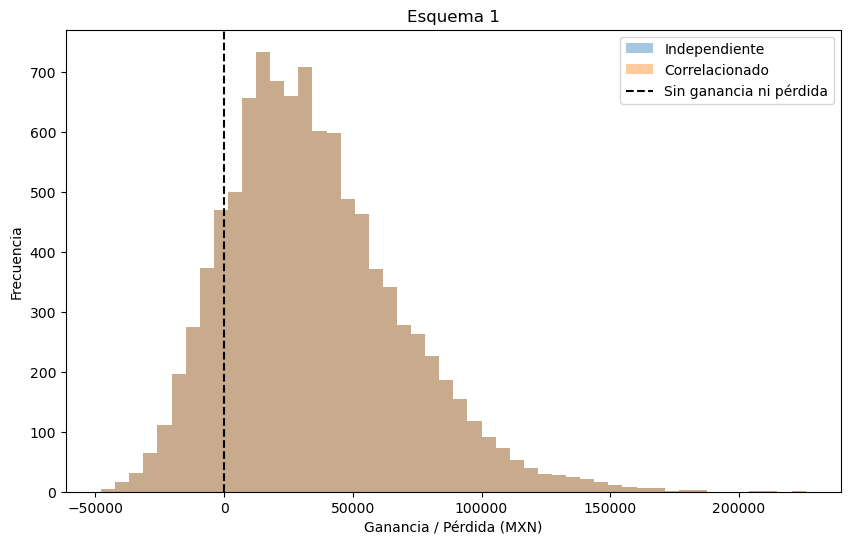

In [16]:
plt.figure(figsize=(10, 6))
plt.hist(PnL_ind2['Esquema 1'], bins=50, alpha=0.4, label='Independiente')
plt.hist(PnL_corr2['Esquema 1'], bins=50, alpha=0.4, label='Correlacionado')
plt.axvline(0, color='black', linestyle='--', label='Sin ganancia ni pérdida')
plt.title('Esquema 1')
plt.xlabel('Ganancia / Pérdida (MXN)')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

Aquí todo está invertido en Apple. Las distribuciones salen iguales porque no estoy combinando varias acciones.

### Esquema 2

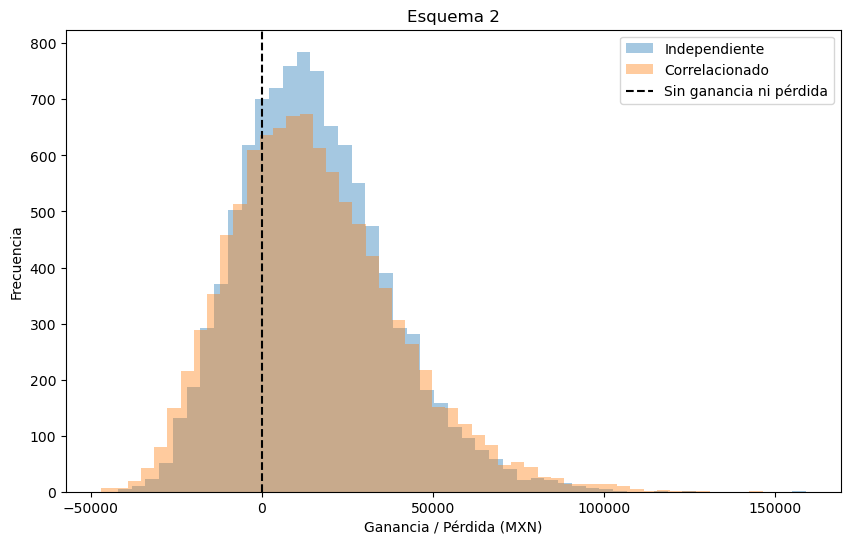

In [17]:
plt.figure(figsize=(10, 6))
plt.hist(PnL_ind2['Esquema 2'], bins=50, alpha=0.4, label='Independiente')
plt.hist(PnL_corr2['Esquema 2'], bins=50, alpha=0.4, label='Correlacionado')
plt.axvline(0, color='black', linestyle='--', label='Sin ganancia ni pérdida')
plt.title('Esquema 2')
plt.xlabel('Ganancia / Pérdida (MXN)')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

Aquí repartí el dinero casi por partes iguales. Al considerar la correlación puede cambiar el riesgo porque las tres acciones no se mueven de manera independiente.

### Esquema 3

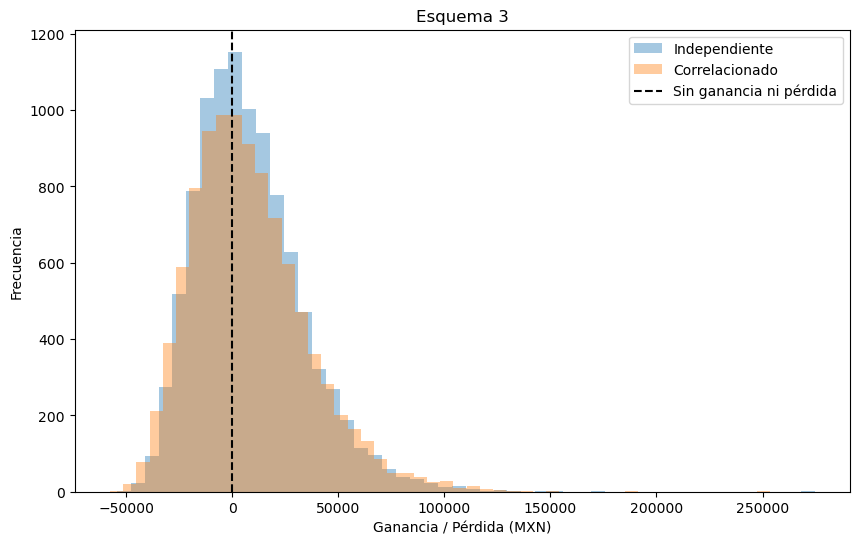

In [18]:
plt.figure(figsize=(10, 6))
plt.hist(PnL_ind2['Esquema 3'], bins=50, alpha=0.4, label='Independiente')
plt.hist(PnL_corr2['Esquema 3'], bins=50, alpha=0.4, label='Correlacionado')
plt.axvline(0, color='black', linestyle='--', label='Sin ganancia ni pérdida')
plt.title('Esquema 3')
plt.xlabel('Ganancia / Pérdida (MXN)')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

En este último esquema invertí 60% en Nvidia. Por eso el resultado depende más de esa acción, pero las correlaciones con Apple y Microsoft también influyen.

# Conclusión

Con esta tarea pude ver que no es lo mismo simular las acciones por separado que tomar en cuenta cómo se relacionan. En el primer ejercicio, aunque las empresas sean de sectores distintos, pueden tener correlación. En el segundo, cuando invierto todo en Apple no hay diferencia, pero al combinar las tres acciones sí puede cambiar el riesgo. Por eso considero que es importante tomar en cuenta las correlaciones al simular un portafolio.